# 02 Settling kinetics: model selection

Candidate curve models fitted to each jar (T0 fixed at the measured value, least squares on log10 turbidity). Jar fits are independent, so no information passes between days.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

from src.config import DATA_PROC, RESULTS, SED_TIMES, SEED
from src import kinetics as kin
from src import style

style.apply()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
STATS = RESULTS / "stats"
SUBSET = None

| Model | Equation (f = T∞/T0) | Parameters |
|---|---|---|
| no_floor | T = T0 exp(−kt) | k |
| first_order | T = T0 [f + (1 − f) exp(−kt)] | k, f |
| first_order_lag | as first_order with t → max(0, t − lag) | k, f, lag |
| stretched | T = T0 [f + (1 − f) exp(−(kt)^β)] | k, f, β |
| second_order | T = T0 [f + (1 − f) / (1 + kt)] | k, f |
| san | T = T0 / [1 + (t/τ)^b] | τ, b |
| san_floor | T = T0 [f + (1 − f) / (1 + (t/τ)^b)] | τ, b, f |

San (1989) Eq. 1 gives removal P = 1/(1 + a H^k T^(−b)). At one sampling depth a H^k is a single constant (written τ^b), so k and the flocculation coefficient are not identifiable. san_floor adds a residual floor (not in the original); second_order is san_floor with b = 1.

## 1. Data

In [2]:
long = pd.read_csv(DATA_PROC / "long.csv", parse_dates=["date"])
runs = pd.read_csv(DATA_PROC / "runs.csv", parse_dates=["date"])
if SUBSET:
    keep = runs["run"].sample(SUBSET, random_state=SEED)
    long, runs = long[long["run"].isin(keep)], runs[runs["run"].isin(keep)].reset_index(drop=True)
MODELS = list(kin.SPECS)
print(long["run"].nunique(), "runs,", len(MODELS), "models")

168 runs, 7 models


## 2. Fit all jars on 10 to 60 min (18 points per jar)

In [3]:
rows, curves = [], []
for run, g in long.groupby("run"):
    T0 = g["t0"].iloc[0]
    d = g[g["sed"] > 0]
    t, y = d["sed"].to_numpy(float), d["turb"].to_numpy()
    for m in MODELS:
        r = kin.fit(m, t, y, T0)
        row = {"run": run, "model": m, "T0": T0}
        row.update({k: r[k] for k in ["n", "p", "sse", "rmse", "aicc", "ss_pe", "df_pe", "ss_lof", "df_lof", "lof_p"]})
        row.update(r["params"])
        row.update({f"se_{k}": v for k, v in r["se"].items()})
        row.update({f"bound_{k}": v for k, v in r["at_bound"].items()})
        rows.append(row)
        curves.append(pd.DataFrame({"run": run, "model": m, "sed": SED_TIMES[1:],
                                    "pred": kin.predict(m, SED_TIMES[1:], T0, list(r["params"].values()))}))
fits = pd.DataFrame(rows)
curves = pd.concat(curves, ignore_index=True)

fits["d_aicc"] = fits["aicc"] - fits.groupby("run")["aicc"].transform("min")
fits["weight"] = np.exp(-0.5 * fits["d_aicc"])
fits["weight"] /= fits.groupby("run")["weight"].transform("sum")
fits.head()

,run,model,T0,n,p,sse,rmse,aicc,ss_pe,df_pe,ss_lof,df_lof,lof_p,k,se_k,bound_k,f,se_f,bound_f,lag,se_lag,bound_lag,beta,se_beta,bound_beta,tau,b,se_tau,se_b,bound_tau,bound_b,d_aicc,weight
0,0,no_floor,223.0,18,1,0.031273,0.041682,-112.146860,0.00211,12,0.029163,5,0.000001,0.021431,0.000598,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.001050,1.703081e-08
1,0,first_order,223.0,18,2,0.010884,0.024590,-128.595210,0.00211,12,0.008774,4,0.000310,0.036380,0.003164,False,2.197702e-01,0.026372,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.552700,6.352564e-05
2,0,first_order_lag,223.0,18,3,0.003302,0.013545,-147.147910,0.00211,12,0.001193,3,0.133568,0.055855,0.003929,False,2.831842e-01,0.010969,False,5.534466,0.683696,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,6.786044e-01
3,0,stretched,223.0,18,3,0.004482,0.015780,-141.649538,0.00211,12,0.002373,3,0.024593,0.043207,0.001415,False,3.059819e-01,0.011728,False,NaN,NaN,NaN,1.428729,0.099185,False,NaN,NaN,NaN,NaN,NaN,NaN,5.498371,4.341707e-02
4,0,second_order,223.0,18,2,0.017326,0.031025,-120.226983,0.00211,12,0.015216,4,0.000020,0.036457,0.005898,False,1.759074e-17,0.061750,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,26.920927,9.678582e-07


## 3. Fit quality against replicate noise

In [4]:
pe = fits.drop_duplicates("run")
pooled_pe_sd = np.sqrt(pe["ss_pe"].sum() / pe["df_pe"].sum())
print(f"pooled replicate SD of log10 turbidity (10-60 min): {pooled_pe_sd:.4f}")

g = fits.groupby("model")
summary = pd.DataFrame({
    "p": g["p"].first(),
    "rmse_median": g["rmse"].median(),
    "rmse_q90": g["rmse"].quantile(0.9),
    "aicc_total": g["aicc"].sum(),
    "best_by_aicc": fits.loc[fits.groupby("run")["aicc"].idxmin(), "model"].value_counts(),
    "mean_akaike_weight": g["weight"].mean(),
    "lof_reject_pct": g["lof_p"].agg(lambda s: 100 * (s < 0.05).mean()),
})
sums = g[["ss_lof", "df_lof", "ss_pe", "df_pe"]].sum()
summary["pooled_lof_F"] = (sums["ss_lof"] / sums["df_lof"]) / (sums["ss_pe"] / sums["df_pe"])
summary = summary.fillna({"best_by_aicc": 0}).loc[MODELS]
summary["rmse_median_over_noise"] = summary["rmse_median"] / pooled_pe_sd
summary.round(4).to_csv(STATS / "kinetic_model_summary.csv")
summary.round(4)

pooled replicate SD of log10 turbidity (10-60 min): 0.0198


,p,rmse_median,rmse_q90,aicc_total,best_by_aicc,mean_akaike_weight,lof_reject_pct,pooled_lof_F,rmse_median_over_noise
model,,,,,,,,,
no_floor,1,0.0693,0.2138,-15356.8250,0.0,0.0057,96.4286,134.0277,3.5076
first_order,2,0.0349,0.0619,-19643.3780,8.0,0.0348,88.6905,16.8682,1.7670
first_order_lag,3,0.0256,0.0576,-20676.6710,35.0,0.2031,64.8810,15.4101,1.2976
stretched,3,0.0208,0.0319,-22536.8849,22.0,0.1811,39.2857,3.8694,1.0552
second_order,2,0.0295,0.0671,-20183.3752,18.0,0.0925,77.9762,19.7795,1.4916
san,2,0.0245,0.0346,-22108.9587,47.0,0.2117,56.5476,4.6896,1.2377
san_floor,3,0.0202,0.0298,-22812.9476,38.0,0.2711,36.3095,3.2301,1.0209


Residuals by settling time (log10 of the triplicate geometric mean minus the fitted value).

In [5]:
obs = long[long["sed"] > 0].assign(ly=np.log10(long["turb"])).groupby(["run", "sed"])["ly"].mean().rename("obs")
res = curves.join(obs, on=["run", "sed"])
res["resid"] = res["obs"] - np.log10(res["pred"])
res_tab = res.groupby(["model", "sed"])["resid"].agg(["mean", "median", "std"]).unstack("sed")["median"].loc[MODELS]
res_tab.round(4)

sed,10,20,30,40,50,60
model,,,,,,
no_floor,-0.0385,-0.0775,-0.0776,-0.0361,0.0156,0.0859
first_order,0.0152,0.0134,0.0146,0.0091,-0.0073,-0.0153
first_order_lag,-0.0054,0.0004,0.0115,0.0122,-0.0028,-0.0116
stretched,0.0077,-0.0065,-0.0015,0.0030,0.0022,-0.0031
second_order,0.0360,0.0206,0.0075,-0.0031,-0.0126,-0.0095
san,0.0174,-0.0015,-0.0065,-0.0069,-0.0015,0.0117
san_floor,0.0026,-0.0029,0.0007,0.0016,-0.0001,-0.0009


figures/kinetics/fig01_residuals_by_time.png


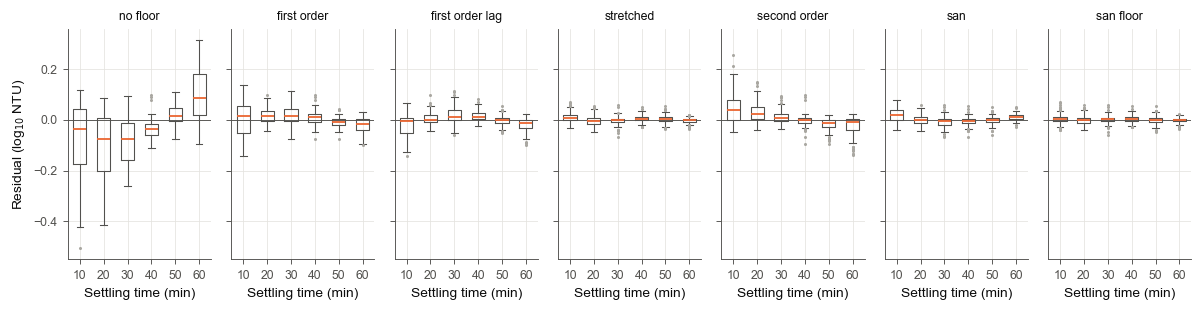

In [6]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(11, 2.9), sharey=True)
times = SED_TIMES[1:]
for ax, m in zip(axes, MODELS):
    r = res[res["model"] == m]
    ax.boxplot([r.loc[r["sed"] == s, "resid"] for s in times], positions=range(len(times)), widths=0.55,
               medianprops=dict(color=style.COLORS[1], lw=1.2), boxprops=dict(color=style.INK2, lw=0.7),
               whiskerprops=dict(color=style.INK2, lw=0.7), capprops=dict(color=style.INK2, lw=0.7),
               flierprops=dict(marker="o", ms=2, mfc=style.MUTED, mec="none"))
    ax.axhline(0, color=style.INK2, lw=0.6)
    ax.set_xticks(range(len(times)), times)
    ax.set_title(m.replace("_", " "), fontsize=8)
    ax.set_xlabel("Settling time (min)")
axes[0].set_ylabel("Residual (log$_{10}$ NTU)")
fig.tight_layout()
print(style.save(fig, "fig01_residuals_by_time", "kinetics"))
plt.show()

figures/kinetics/fig02_fit_quality.png


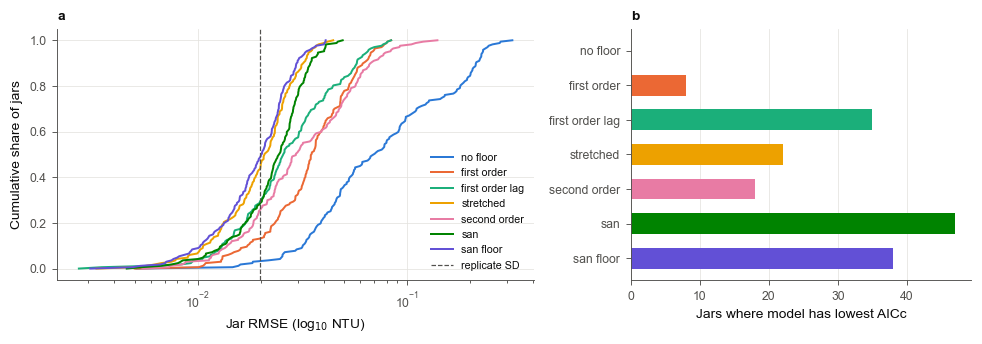

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
for i, m in enumerate(MODELS):
    v = np.sort(fits.loc[fits["model"] == m, "rmse"])
    ax.plot(v, np.linspace(0, 1, len(v)), color=style.COLORS[i], lw=1.3, label=m.replace("_", " "))
ax.axvline(pooled_pe_sd, color=style.INK2, lw=0.8, ls="--", label="replicate SD")
ax.set_xscale("log")
ax.set_xlabel("Jar RMSE (log$_{10}$ NTU)")
ax.set_ylabel("Cumulative share of jars")
ax.legend(loc="lower right", fontsize=7)
style.panel_label(ax, "a")

ax = axes[1]
w = summary["best_by_aicc"]
ax.barh(range(len(MODELS)), w.values, color=[style.COLORS[i] for i in range(len(MODELS))], height=0.6)
ax.set_yticks(range(len(MODELS)), [m.replace("_", " ") for m in MODELS])
ax.invert_yaxis()
ax.set_xlabel("Jars where model has lowest AICc")
ax.grid(axis="y", visible=False)
style.panel_label(ax, "b")
fig.tight_layout()
print(style.save(fig, "fig02_fit_quality", "kinetics"))
plt.show()

## 4. Parameter identifiability

In [8]:
ident = []
for m in MODELS:
    d = fits[fits["model"] == m]
    for prm in kin.SPECS[m][1]:
        free = ~d[f"bound_{prm}"].astype(bool)
        rel = (d[f"se_{prm}"] / d[prm].abs())[free]
        ident.append({"model": m, "param": prm,
                      "median": d[prm].median(), "q10": d[prm].quantile(0.1), "q90": d[prm].quantile(0.9),
                      "at_bound_pct": 100 * d[f"bound_{prm}"].astype(bool).mean(),
                      "median_rel_se_free": rel.median(), "rel_se_gt_0.5_pct_free": 100 * (rel > 0.5).mean()})
ident = pd.DataFrame(ident)
ident.round(4).to_csv(STATS / "kinetic_identifiability.csv", index=False)
ident.round(3)

,model,param,median,q10,q90,at_bound_pct,median_rel_se_free,rel_se_gt_0.5_pct_free
0,no_floor,k,0.028,0.011,0.050,0.000,0.047,0.000
1,first_order,k,0.052,0.011,0.123,0.000,0.071,13.690
2,first_order,f,0.107,0.000,0.262,22.024,0.058,10.687
3,first_order_lag,k,0.063,0.022,0.123,0.000,0.143,8.929
4,first_order_lag,f,0.174,0.069,0.380,5.952,0.062,9.494
5,first_order_lag,lag,1.366,0.000,14.162,48.810,0.186,12.791
6,stretched,k,0.049,0.024,0.180,0.000,0.058,5.952
7,stretched,f,0.170,0.031,0.479,5.357,0.099,6.918
8,stretched,beta,1.054,0.480,2.290,2.976,0.092,1.840
9,second_order,k,0.075,0.014,0.252,0.000,0.144,16.667


## 5. Extrapolation check: fit on 10 to 40 min, predict 50 and 60 min

In [9]:
ext = []
for run, g in long.groupby("run"):
    T0 = g["t0"].iloc[0]
    tr = g[(g["sed"] > 0) & (g["sed"] <= 40)]
    te = obs.loc[run].loc[[50, 60]]
    for m in MODELS:
        r = kin.fit(m, tr["sed"].to_numpy(float), tr["turb"].to_numpy(), T0)
        p = np.log10(kin.predict(m, [50, 60], T0, list(r["params"].values())))
        ext.append({"run": run, "model": m, "rmse_50_60": np.sqrt(np.mean((p - te.values) ** 2)),
                    "bias_50_60": np.mean(p - te.values)})
ext = pd.DataFrame(ext)
ext_tab = ext.groupby("model")[["rmse_50_60", "bias_50_60"]].agg(["median", "mean"]).loc[MODELS]
ext_tab.round(4).to_csv(STATS / "kinetic_extrapolation.csv")
ext_tab.round(4)

rmse_50_60         bias_50_60        
                    median    mean     median    mean
model                                                
no_floor            0.1664  0.2141    -0.1458 -0.1770
first_order         0.0680  0.0747     0.0483  0.0436
first_order_lag     0.0625  0.0702     0.0512  0.0551
stretched           0.0427  0.0576     0.0300  0.0343
second_order        0.0375  0.0510     0.0279  0.0425
san                 0.0382  0.0475    -0.0274 -0.0304
san_floor           0.0290  0.0418     0.0139  0.0207

## 6. Example fits

figures/kinetics/fig03_example_fits.png


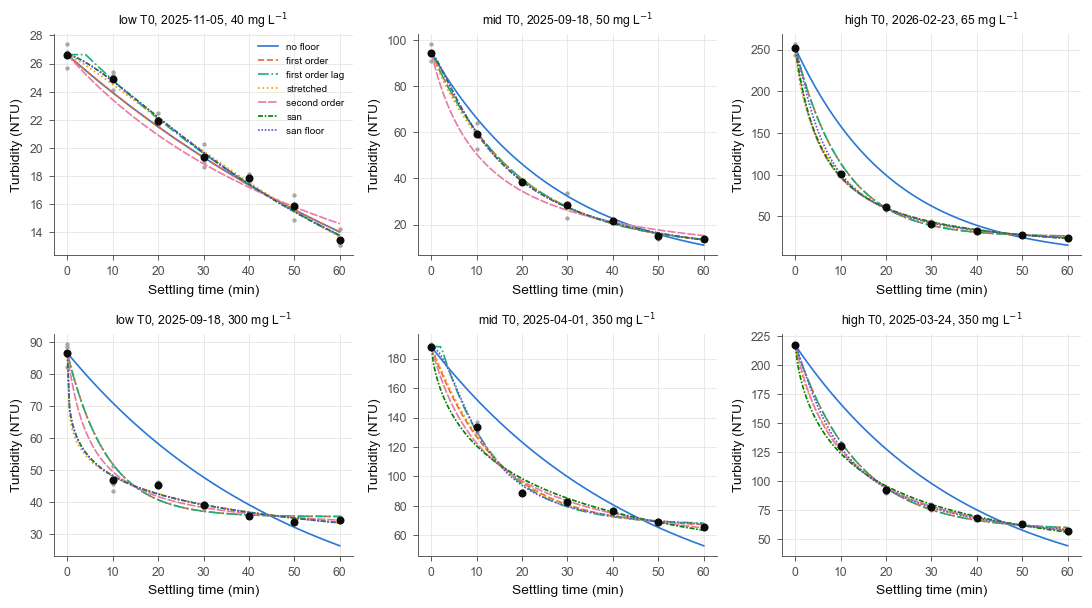

In [10]:
r = runs.assign(t0_bin=pd.qcut(runs["T0"], 3, labels=["low T0", "mid T0", "high T0"]))
ex = pd.concat([g.loc[[g["dose"].idxmin(), g["dose"].idxmax()]] for _, g in r.groupby("t0_bin", observed=True)])
tt = np.linspace(0, 60, 121)
styles = ["-", "--", "-.", ":", (0, (5, 1)), (0, (3, 1, 1, 1)), (0, (1, 1))]

fig, axes = plt.subplots(2, 3, figsize=(10, 5.6))
for ax, (_, row) in zip(axes.T.ravel(), ex.iterrows()):
    g = long[long["run"] == row["run"]]
    ax.scatter(g["sed"], g["turb"], s=8, color=style.MUTED, lw=0, zorder=1)
    cm = g.groupby("sed")["turb"].mean()
    ax.scatter(cm.index, cm.values, s=18, color=style.INK, zorder=3)
    T0 = g["t0"].iloc[0]
    for i, m in enumerate(MODELS):
        prm = fits.loc[(fits["run"] == row["run"]) & (fits["model"] == m), kin.SPECS[m][1]].iloc[0].tolist()
        ax.plot(tt, kin.predict(m, tt, T0, prm), color=style.COLORS[i], ls=styles[i], lw=1.1,
                label=m.replace("_", " "), zorder=2)
    ax.set_title(f"{row['t0_bin']}, {row['date']:%Y-%m-%d}, {row['dose']:.0f} mg L$^{{-1}}$", fontsize=8)
    ax.set_xlabel("Settling time (min)")
    ax.set_ylabel("Turbidity (NTU)")
axes[0, 0].legend(fontsize=6.5, loc="upper right")
fig.tight_layout()
print(style.save(fig, "fig03_example_fits", "kinetics"))
plt.show()

## 7. Parameters against dose

figures/kinetics/fig04_params_vs_dose.png


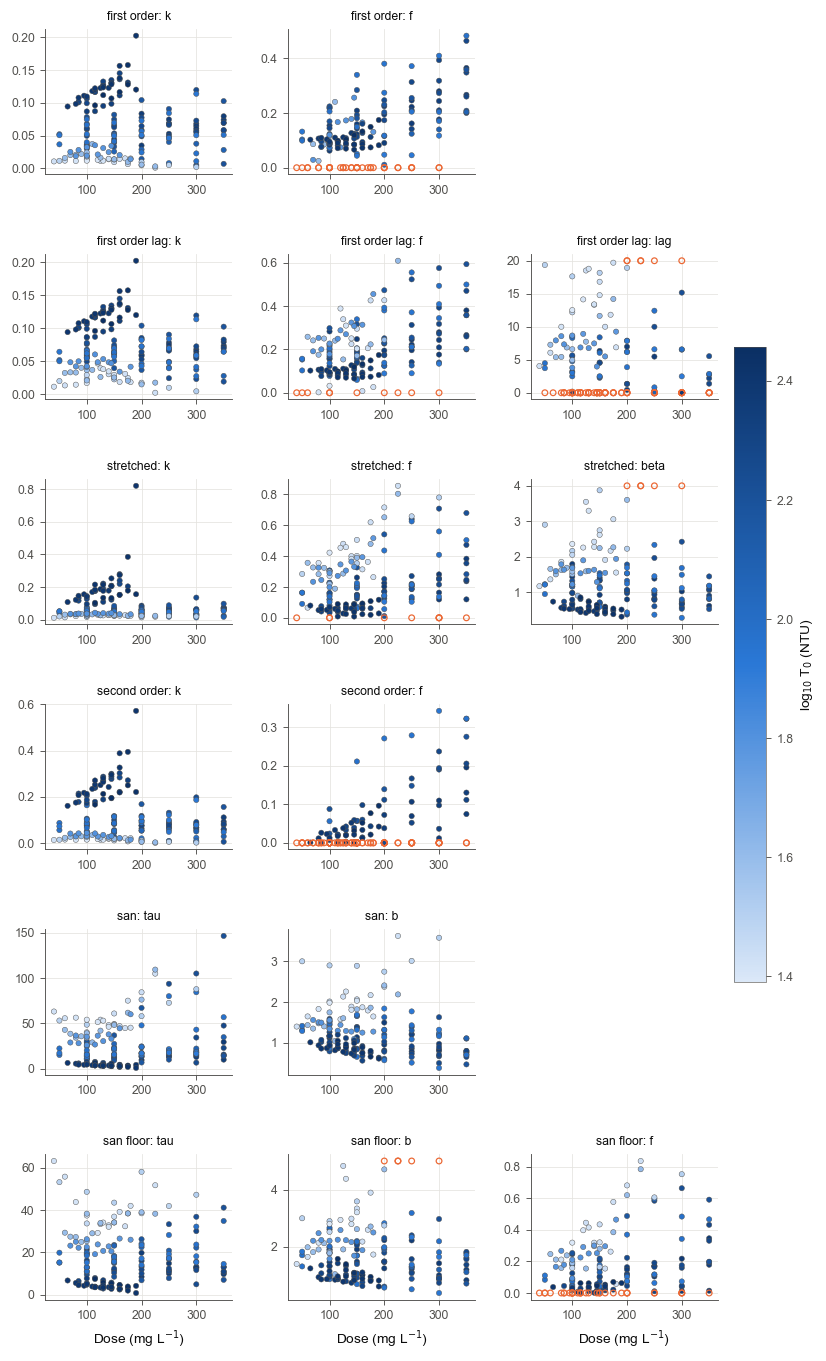

In [11]:
multi = [m for m in MODELS if kin.SPECS[m][1] != ["k"]]
ncol = max(len(kin.SPECS[m][1]) for m in multi)
tnorm = Normalize(np.log10(runs["T0"].min()), np.log10(runs["T0"].max()))
fig, axes = plt.subplots(len(multi), ncol, figsize=(9.5, 2.5 * len(multi)), squeeze=False)
for i, m in enumerate(multi):
    d = fits[fits["model"] == m].merge(runs[["run", "dose"]], on="run")
    for j in range(ncol):
        ax = axes[i, j]
        if j >= len(kin.SPECS[m][1]):
            ax.axis("off")
            continue
        prm = kin.SPECS[m][1][j]
        free = ~d[f"bound_{prm}"].astype(bool)
        c = style.SEQ(tnorm(np.log10(d["T0"])))
        ax.scatter(d.loc[free, "dose"], d.loc[free, prm], c=c[free.values], s=12, lw=0.3, edgecolor=style.INK2)
        ax.scatter(d.loc[~free, "dose"], d.loc[~free, prm], s=14, facecolor="none", edgecolor=style.COLORS[1], lw=0.8)
        ax.set_title(f"{m.replace('_', ' ')}: {prm}", fontsize=8)
        if i == len(multi) - 1:
            ax.set_xlabel("Dose (mg L$^{-1}$)")
fig.subplots_adjust(hspace=0.55, wspace=0.3)
cb = fig.colorbar(plt.cm.ScalarMappable(norm=tnorm, cmap=style.SEQ), ax=axes, shrink=0.5, pad=0.02)
cb.set_label("log$_{10}$ T$_0$ (NTU)")
cb.outline.set_linewidth(0.4)
print(style.save(fig, "fig04_params_vs_dose", "kinetics"))
plt.show()

Open orange markers: parameter at a bound.

## 8. Save

In [12]:
fits.merge(runs[["run", "day", "batch", "date", "speed", "mtime", "dose"]], on="run").to_csv(
    DATA_PROC / "kinetic_fits.csv", index=False)
res.to_csv(STATS / "kinetic_residuals.csv", index=False)
ext.to_csv(STATS / "kinetic_extrapolation_by_run.csv", index=False)
print(fits.shape, res.shape, ext.shape)

(1176, 33) (7056, 6) (1176, 4)
